# 03 · Robustness Diagnostics, Interpretation and Findings

**PhilGEPS procurement-failure risk · Notebook 3 of 3 · Roadmap steps 7–9**
**Inputs:** the bid table from notebook 01 (2023 Q1 – 2026 Q2, `Closed` bids removed), plus the split assignment and final model from notebook 02.
**Outcome:** procurement failure, `Target_Failed` = 1 for `Failed` or `Cancelled` bids, 0 for `Awarded` bids.

| Section | Question |
|---|---|
| 7.1 | What did the final model achieve on the random test set? |
| 7.2 | Does the model hold up on **later periods** it has not seen (train on 2023–2024, test on 2025 and 2026)? |
| 7.3 | Which inputs changed between periods and systems (drift)? |
| 7.4 | Where does the model work well, by classification and by quarter? |
| 7.5 | How much do incomplete labels limit the conclusions? |
| 8.1 | Which inputs does the model rely on? |
| 8.2–8.4 | How does the failure rate relate to budget size and procurement type? This is descriptive, not causal. |
| 8.5 | What would a review queue based on the score catch? |
| 9 | Findings, limitations, and answers to the reviewer's questions |

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.inspection import permutation_importance

import procurement_failure as pf

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

bids = pd.read_parquet(pf.BIDS)
splits = pd.read_parquet(pf.SPLITS)
config = json.loads((pf.MODELS / "final_config.json").read_text())
final = joblib.load(pf.MODELS / "final_pipeline.joblib")
calibrated = joblib.load(pf.MODELS / "final_calibrated.joblib")
numeric, categorical = config["numeric"], config["categorical"]

for c in pf.KEY:
    bids[c] = bids[c].astype(str); splits[c] = splits[c].astype(str)
labelled = bids[bids.Target_Failed.notna()].merge(splits, on=pf.KEY, how="left")
assert labelled["split"].notna().all()
test = labelled[labelled.split == "test"].copy()
test["prob"] = calibrated.predict_proba(pf.model_frame(test, numeric, categorical))[:, 1]
print(f"Final model: {config['model']} ({config['feature_set']} features)")
print(f"Labelled bids: {len(labelled):,} | test: {len(test):,}")

Final model: Gradient boosting (expanded features)
Labelled bids: 615,398 | test: 92,310


## Phase 7. Robustness diagnostics

### 7.1 Recap: random-split test performance

In [2]:
recap = pd.DataFrame([{"Evaluation": "Random split, test set", **pf.summary_metrics(test.Target_Failed, test.prob)}])
display(recap)
display(pf.queue_metrics(test.Target_Failed, test.prob))

,Evaluation,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,"Random split, test set",92310,0.2001,0.7655,0.5039,0.6056,0.3027,3.0270


,Review share,Notices reviewed,Precision@k,Recall@k,Lift@k
0,top 5%,4616,0.7270,0.1817,3.6342
1,top 10%,9231,0.6056,0.3027,3.0270
2,top 20%,18462,0.4744,0.4743,2.3715
3,top 30%,27693,0.4052,0.6077,2.0256
4,top 50%,46155,0.3182,0.7954,1.5907


### 7.2 Out-of-time check: train on 2023–2024, test on later periods

A random split lets the model learn from every period, including the one it is tested on. In practice, a score would be trained on past notices and applied to new ones. The final configuration is therefore refitted on bids **published in 2023–2024** (all PhilGEPS 1.5) and evaluated on:

- 2025 (PhilGEPS 1.5),
- 2026 Q1–Q2 PhilGEPS 1.5 notices,
- 2026 Q1–Q2 PhilGEPS 2.0 notices. The 2.0 vocabularies for category and funding source were never seen in 2023–2024.

The model is evaluated on raw scores (ranking metrics only). Calibration fitted on the random split would not transfer to a different period.

In [3]:
from sklearn.base import clone

past = labelled[labelled.published_year <= 2024]
oot_model = clone(final).fit(pf.model_frame(past, numeric, categorical), past.Target_Failed.astype(int))

periods = {
    "2025, PhilGEPS 1.5": labelled[(labelled.published_year == 2025) & (labelled["Source System"] == "1.5")],
    "2026, PhilGEPS 1.5": labelled[(labelled.published_year == 2026) & (labelled["Source System"] == "1.5")],
    "2026, PhilGEPS 2.0": labelled[(labelled.published_year == 2026) & (labelled["Source System"] == "2.0")],
}
rows = []
for name, frame in periods.items():
    score = oot_model.predict_proba(pf.model_frame(frame, numeric, categorical))[:, 1]
    rows.append({"Evaluation": f"Trained 2023–2024 → {name}", **pf.summary_metrics(frame.Target_Failed, score)})
    sub = test[(test.published_year == frame.published_year.iloc[0]) & (test["Source System"] == frame["Source System"].iloc[0])]
    rows.append({"Evaluation": f"Random split → same period ({name}), test bids only", **pf.summary_metrics(sub.Target_Failed, sub.prob)})
oot = pd.DataFrame(rows)
display(oot)
print(f"Training bids (2023–2024): {len(past):,}, failure rate {past.Target_Failed.mean() * 100:.2f}%")

,Evaluation,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,"Trained 2023–2024 → 2025, PhilGEPS 1.5",121383,0.2316,0.7404,0.5170,0.6240,0.2694,2.6940
1,"Random split → same period (2025, PhilGEPS 1.5...",18157,0.2277,0.7790,0.5657,0.6872,0.3018,3.0176
2,"Trained 2023–2024 → 2026, PhilGEPS 1.5",65151,0.2235,0.6850,0.4314,0.5216,0.2334,2.3337
3,"Random split → same period (2026, PhilGEPS 1.5...",9710,0.2261,0.7490,0.5114,0.6066,0.2683,2.6834
4,"Trained 2023–2024 → 2026, PhilGEPS 2.0",8478,0.3838,0.6211,0.5255,0.6439,0.1678,1.6775
5,"Random split → same period (2026, PhilGEPS 2.0...",1272,0.3836,0.7636,0.6760,0.7953,0.2070,2.0729


Training bids (2023–2024): 420,386, failure rate 18.36%


### 7.3 Drift: inputs never seen in training

A large share of unseen category values points to reporting or schema changes rather than a change in procurement behaviour. This is the main issue LT8 found for 2026 (LT8 §7.2), where 2026 came only from the 2.0 exports.

In [4]:
seen = {c: set(past[c].astype("string").fillna("Missing")) for c in categorical if c in past}
drift_rows = []
for name, frame in periods.items():
    row = {"Period": name, "Bids": len(frame)}
    for c in categorical:
        vals = frame[c].astype("string").fillna("Missing")
        row[c] = round((~vals.isin(seen[c])).mean() * 100, 1)
    drift_rows.append(row)
drift = pd.DataFrame(drift_rows).set_index("Period")
print("Share of bids (%) with a value not seen in 2023–2024 training data:")
display(drift)

Share of bids (%) with a value not seen in 2023–2024 training data:


,Bids,Funding Source,Business Category,Region,published_month,Classification,PE Organization Type (Grouped),Government Branch,Funding Instrument,Trade Agreement,Lot Type,published_dayofweek,Source System
Period,,,,,,,,,,,,,
"2025, PhilGEPS 1.5",121383,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
"2026, PhilGEPS 1.5",65151,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
"2026, PhilGEPS 2.0",8478,100.0000,99.7000,0.0000,0.0000,0.0000,0.1000,2.4000,100.0000,0.0000,100.0000,0.0000,100.0000


### 7.4 Performance by procurement classification and by quarter

Segment results on the random test set. Small segments (under 200 bids or a single class) are omitted. A high precision in a segment can simply reflect a high base failure rate, so read precision together with lift.

,Classification,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,Civil Works,38653,0.1508,0.7467,0.4218,0.4849,0.3216,3.2163
1,Consulting Services,517,0.3830,0.7052,0.5579,0.6731,0.1768,1.7575
2,Goods,51306,0.2311,0.7626,0.5357,0.6634,0.2871,2.8704
3,Goods - General Support Services,1834,0.3184,0.6972,0.5566,0.7049,0.2209,2.2137


,published_quarter,Source System,n,failure rate,ROC-AUC,PR-AUC,Precision@10%,Recall@10%,Lift@10%
0,2023Q1,1.5,6964,0.1771,0.7834,0.5197,0.6049,0.3414,3.4164
1,2023Q2,1.5,7575,0.2077,0.7594,0.5040,0.6095,0.2937,2.9351
2,2023Q3,1.5,7060,0.1901,0.7679,0.4919,0.5878,0.3092,3.0924
3,2023Q4,1.5,8236,0.1748,0.7372,0.4019,0.4830,0.2764,2.7625
4,2024Q1,1.5,7605,0.1737,0.7692,0.5113,0.6000,0.3452,3.4542
5,2024Q2,1.5,7896,0.1763,0.7708,0.4665,0.5506,0.3125,3.1234
6,2024Q3,1.5,8101,0.1878,0.7619,0.4597,0.5259,0.2801,2.8011
7,2024Q4,1.5,9734,0.1877,0.7618,0.4712,0.5642,0.3005,3.0062
8,2025Q1,1.5,8413,0.1733,0.7979,0.5547,0.6468,0.3731,3.7325
9,2025Q2,1.5,4522,0.2043,0.7567,0.4949,0.6062,0.2965,2.9667


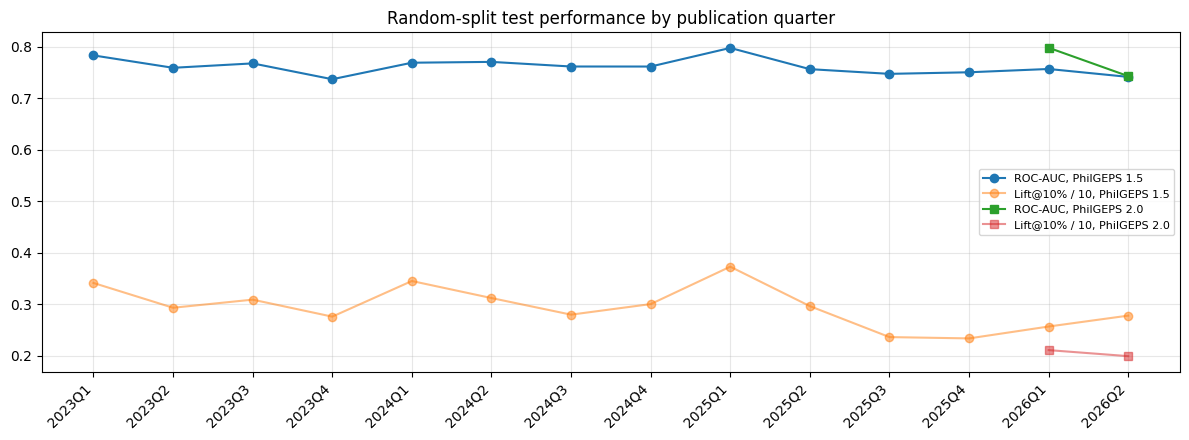

In [5]:
def by_group(frame, cols):
    rows = []
    for g, sub in frame.groupby(cols, observed=True):
        if sub.Target_Failed.nunique() == 2 and len(sub) >= 200:
            g = g if isinstance(g, tuple) else (g,)
            rows.append({**dict(zip(cols, g)), **pf.summary_metrics(sub.Target_Failed, sub.prob)})
    return pd.DataFrame(rows)

display(by_group(test, ["Classification"]))
by_q = by_group(test, ["published_quarter", "Source System"])
display(by_q)

fig, ax = plt.subplots(figsize=(12, 4.5))
for system, style in [("1.5", "-o"), ("2.0", "-s")]:
    s = by_q[by_q["Source System"] == system]
    ax.plot(s.published_quarter.astype(str), s["ROC-AUC"], style, label=f"ROC-AUC, PhilGEPS {system}")
    ax.plot(s.published_quarter.astype(str), s["Lift@10%"] / 10, style, alpha=.5, label=f"Lift@10% / 10, PhilGEPS {system}")
ax.set_title("Random-split test performance by publication quarter"); ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.xticks(rotation=45, ha="right"); plt.tight_layout(); plt.show()

### 7.5 Incomplete labels and outcome-selection bias

The model is trained and evaluated only on bids with a posted outcome (`Awarded`, `Failed` or `Cancelled`). `Closed` bids were removed in notebook 01. Two checks show how far that limits the conclusions:

1. **Label coverage by period.** This is the share of the remaining bids with a final status.
2. **Scores of unlabelled bids.** The model is applied to the bids still without an outcome (`Active`, `Shortlisted`, `Concluded`). The test-set scores for `Failed` and `Cancelled` bids are shown separately, to see whether the model treats the two kinds of failure alike.

bids  labelled      failed  Label coverage (%)  Failure rate among labelled (%)
published_year Source System                                                                                   
2023           1.5            199544    199294 37,457.0000             99.9000                          18.7900
2024           1.5            221340    221092 39,728.0000             99.9000                          17.9700
2025           1.5            135288    121383 28,115.0000             89.7000                          23.1600
2026           1.5             65257     65151 14,561.0000             99.8000                          22.3500
               2.0              8492      8478  3,254.0000             99.8000                          38.3800

bids   mean  median
status      Source System                      
Active      1.5            13809 0.2460  0.2160
            2.0                7 0.3760  0.2480
Awarded     1.5            73059 0.1620  0.1190
            2.0              784 0.2920  0.2480
Cancelled   1.5             8594 0.3120  0.2480
Concluded   2.0                7 0.4030  0.4060
Failed      1.5             9385 0.3750  0.3300
            2.0              488 0.5180  0.4650
Shortlisted 1.5              700 0.3990  0.4060

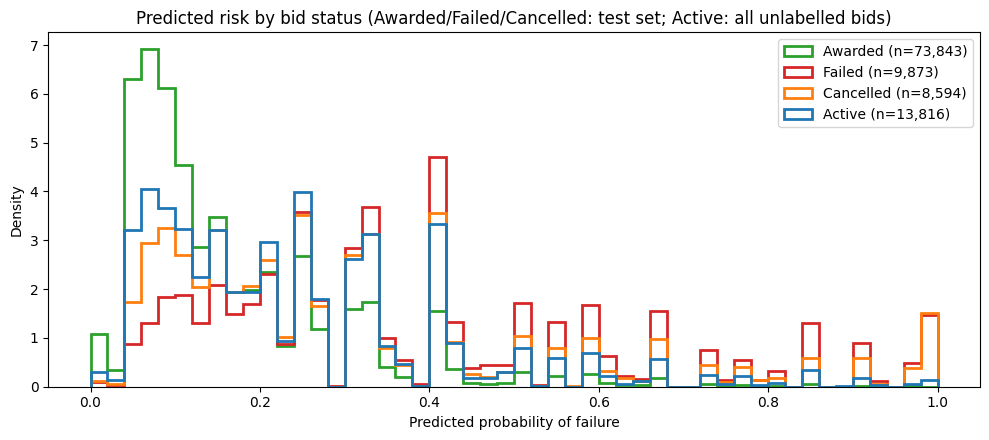

In [6]:
coverage = bids.groupby(["published_year", "Source System"], observed=True).agg(
    bids=("status", "size"), labelled=("Target_Failed", "count"), failed=("Target_Failed", "sum"))
coverage["Label coverage (%)"] = (coverage.labelled / coverage.bids * 100).round(1)
coverage["Failure rate among labelled (%)"] = (coverage.failed / coverage.labelled * 100).round(2)
display(coverage)

unlabelled = bids[bids.Target_Failed.isna() & bids.status.isin(["Active", "Shortlisted", "Concluded"])]
unlabelled_prob = calibrated.predict_proba(pf.model_frame(unlabelled, numeric, categorical))[:, 1]
scores = pd.concat([
    pd.DataFrame({"status": test.status, "Source System": test["Source System"], "predicted risk": test.prob}),
    pd.DataFrame({"status": unlabelled.status.values, "Source System": unlabelled["Source System"].values, "predicted risk": unlabelled_prob}),
])
display(scores.groupby(["status", "Source System"], observed=True)["predicted risk"]
        .agg(bids="size", mean="mean", median="median").round(3))

fig, ax = plt.subplots(figsize=(10, 4.5))
for status, color in [("Awarded", "tab:green"), ("Failed", "tab:red"), ("Cancelled", "tab:orange"), ("Active", "tab:blue")]:
    s = scores.loc[scores.status == status, "predicted risk"]
    ax.hist(s, bins=50, range=(0, 1), density=True, histtype="step", lw=2, label=f"{status} (n={len(s):,})", color=color)
ax.set_xlabel("Predicted probability of failure"); ax.set_ylabel("Density")
ax.set_title("Predicted risk by bid status (Awarded/Failed/Cancelled: test set; Active: all unlabelled bids)")
ax.legend(); plt.tight_layout(); plt.show()

## Phase 8. Interpretation

### 8.1 Permutation importance

Each input is shuffled in turn on a 60,000-bid stratified sample of the test set. The resulting drop in PR-AUC is recorded and averaged over three repeats. Importance measures how much the model depends on an input. It is **not** a causal effect, and correlated inputs share credit.

,Feature,Mean drop in PR-AUC,Std
0,log_approved_budget,0.1443,0.0010
1,Region,0.1408,0.0007
2,Business Category,0.1127,0.0010
3,Funding Instrument,0.0506,0.0020
4,bidding_window_days,0.0490,0.0012
5,log_contract_duration_days,0.0474,0.0008
6,Classification,0.0240,0.0009
7,PE Organization Type (Grouped),0.0211,0.0011
8,published_month,0.0173,0.0006
9,Funding Source,0.0133,0.0008


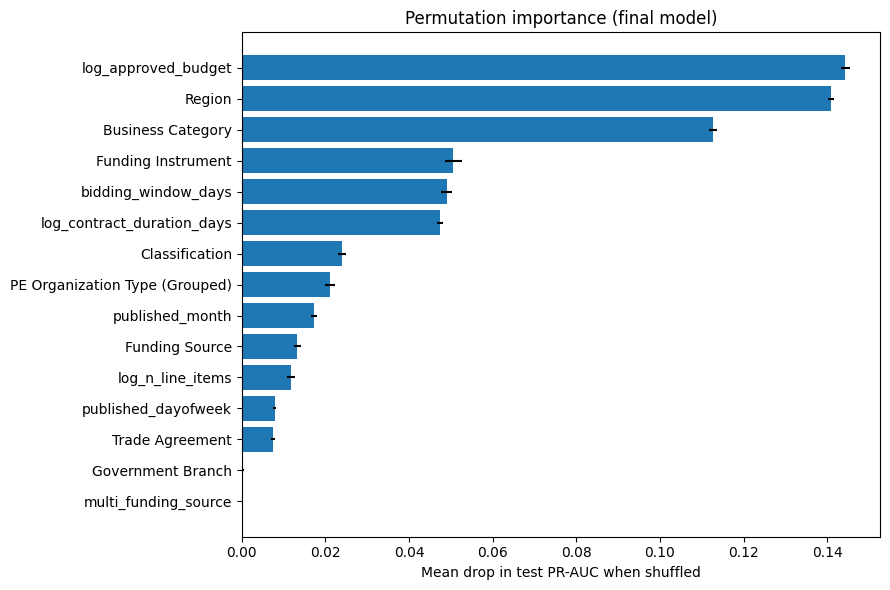

In [7]:
from sklearn.model_selection import train_test_split
sample, _ = train_test_split(test, train_size=min(60_000, len(test) - 1), stratify=test.Target_Failed,
                             random_state=pf.RANDOM_STATE)
X_s = pf.model_frame(sample, numeric, categorical)
imp = permutation_importance(final, X_s, sample.Target_Failed.astype(int), scoring="average_precision",
                             n_repeats=3, random_state=pf.RANDOM_STATE, n_jobs=1)
importance = (pd.DataFrame({"Feature": X_s.columns, "Mean drop in PR-AUC": imp.importances_mean,
                            "Std": imp.importances_std})
              .sort_values("Mean drop in PR-AUC", ascending=False).reset_index(drop=True))
display(importance)

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(9, 6))
plt.barh(top.Feature, top["Mean drop in PR-AUC"], xerr=top.Std, color="tab:blue")
plt.xlabel("Mean drop in test PR-AUC when shuffled"); plt.title("Permutation importance (final model)")
plt.tight_layout(); plt.show()

### 8.2 Observed failure rate by budget decile

Labelled PhilGEPS 1.5 bids are grouped into ten equal-sized bands of approved budget. 2.0 bids are left out so the comparison is not mixed with the 2.0 reporting differences. This is descriptive: it shows where failures concentrate, not that budget size causes failure.

,bids,failure_rate,min,max
budget_decile,,,,
1,61219,0.3918,1.0000,"180,000.0000"
2,60169,0.2617,"180,000.7500","335,500.0000"
3,60688,0.2018,"335,531.0000","579,670.0000"
4,70092,0.1732,"579,671.6000","1,000,000.0000"
5,51340,0.1793,"1,000,000.0100","1,520,000.0000"
6,60644,0.1662,"1,520,024.0000","2,449,674.0000"
7,60755,0.1509,"2,449,693.6200","4,200,000.0000"
8,60630,0.1385,"4,200,036.3000","7,269,000.0000"
9,60691,0.1419,"7,269,200.0000","19,839,435.0000"


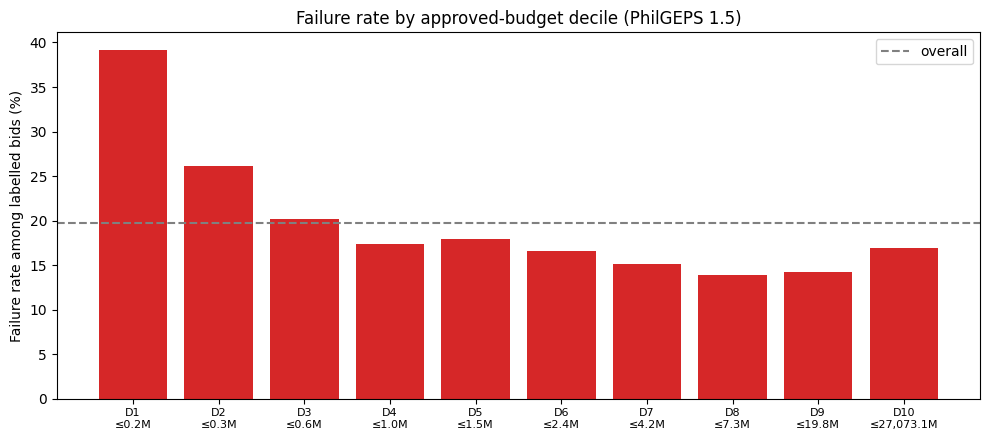

In [8]:
l15 = labelled[labelled["Source System"] == "1.5"].copy()
l15["budget_decile"] = pd.qcut(l15.approved_budget, 10, labels=False) + 1
edges = l15.groupby("budget_decile").approved_budget.agg(["min", "max"])
dec = l15.groupby("budget_decile").Target_Failed.agg(bids="size", failure_rate="mean").join(edges)
display(dec)

plt.figure(figsize=(10, 4.5))
plt.bar(dec.index, dec.failure_rate * 100, color="tab:red")
plt.axhline(l15.Target_Failed.mean() * 100, ls="--", color="gray", label="overall")
plt.xticks(dec.index, [f"D{i}\n≤{m / 1e6:,.1f}M" for i, m in zip(dec.index, dec["max"])], fontsize=8)
plt.ylabel("Failure rate among labelled bids (%)"); plt.title("Failure rate by approved-budget decile (PhilGEPS 1.5)")
plt.legend(); plt.tight_layout(); plt.show()

### 8.3 Budget pattern by classification

Goods and Civil Works have very different budget distributions, so the overall budget pattern can mix two different relationships. The deciles here are the common ones from §8.2.

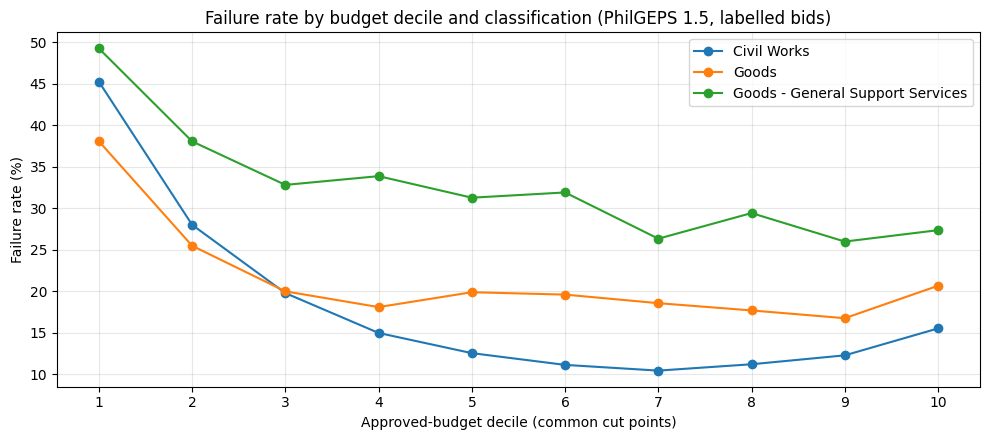

Classification,Civil Works,Goods,Goods - General Support Services
budget_decile,,,
1,0.4528,0.3809,0.4928
2,0.2801,0.2548,0.3807
3,0.1978,0.1999,0.3283
4,0.1497,0.1809,0.3388
5,0.1254,0.1988,0.3128
6,0.1112,0.1960,0.3191
7,0.1043,0.1856,0.2634
8,0.1120,0.1769,0.2943
9,0.1227,0.1675,0.2599


In [9]:
strat = (l15[l15.Classification.isin(["Goods", "Civil Works", "Goods - General Support Services"])]
         .groupby(["Classification", "budget_decile"]).Target_Failed.agg(bids="size", failure_rate="mean").reset_index())
plt.figure(figsize=(10, 4.5))
for cls, sub in strat.groupby("Classification"):
    sub = sub[sub.bids >= 200]
    plt.plot(sub.budget_decile, sub.failure_rate * 100, "o-", label=cls)
plt.xlabel("Approved-budget decile (common cut points)"); plt.ylabel("Failure rate (%)")
plt.title("Failure rate by budget decile and classification (PhilGEPS 1.5, labelled bids)")
plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
display(strat.pivot(index="budget_decile", columns="Classification", values="failure_rate").round(4))

### 8.4 Adjusted failure curves

A logistic regression of `Target_Failed` on budget decile × classification, adjusted for region and publication quarter. It is fitted on labelled PhilGEPS 1.5 Goods and Civil Works bids. The adjusted curves average the model's predictions over each classification's own mix of regions and quarters. This is an association analysis on labelled bids, not a causal estimate.

Observations: 592,060 | pseudo R-squared: 0.0548 | converged: True


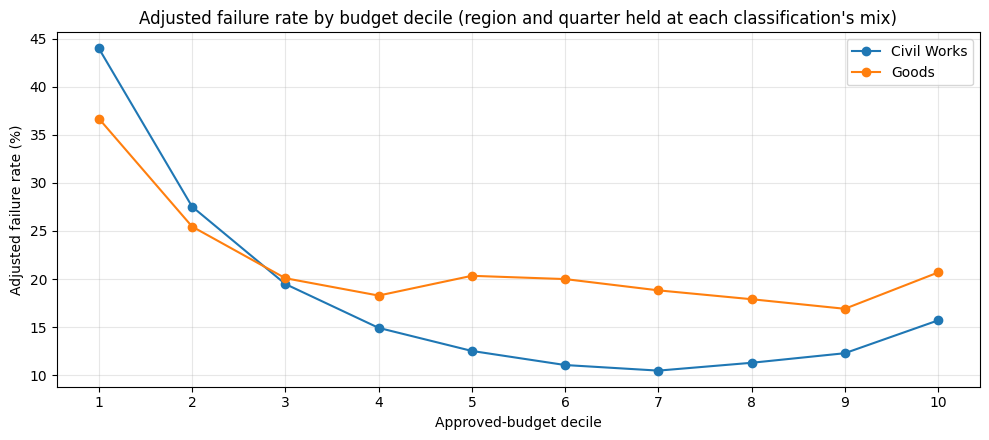

Classification,Civil Works,Goods
budget_decile,,
1,0.4397,0.3668
2,0.2752,0.2545
3,0.1949,0.2009
4,0.1493,0.1829
5,0.1253,0.2034
6,0.1106,0.2000
7,0.1048,0.1883
8,0.1130,0.1790
9,0.1229,0.1691


In [10]:
glm_df = l15[l15.Classification.isin(["Goods", "Civil Works"])][
    ["Target_Failed", "budget_decile", "Classification", "Region", "published_quarter"]].copy()
for c in ["Classification", "Region", "published_quarter"]:
    glm_df[c] = glm_df[c].astype(str)
glm_df["budget_decile"] = glm_df["budget_decile"].astype(int)
glm = smf.logit("Target_Failed ~ C(budget_decile) * C(Classification) + C(Region) + C(published_quarter)",
                data=glm_df).fit(disp=False, maxiter=200)
print(f"Observations: {int(glm.nobs):,} | pseudo R-squared: {glm.prsquared:.4f} | converged: {glm.mle_retvals['converged']}")

curves = []
for cls in ["Goods", "Civil Works"]:
    base = glm_df[glm_df.Classification == cls]
    for d in range(1, 11):
        curves.append({"Classification": cls, "budget_decile": d,
                       "adjusted failure rate": glm.predict(base.assign(budget_decile=d)).mean()})
curves = pd.DataFrame(curves)
plt.figure(figsize=(10, 4.5))
for cls, sub in curves.groupby("Classification"):
    plt.plot(sub.budget_decile, sub["adjusted failure rate"] * 100, "o-", label=cls)
plt.xlabel("Approved-budget decile"); plt.ylabel("Adjusted failure rate (%)")
plt.title("Adjusted failure rate by budget decile (region and quarter held at each classification's mix)")
plt.xticks(range(1, 11)); plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()
display(curves.pivot(index="budget_decile", columns="Classification", values="adjusted failure rate").round(4))

### 8.5 Review-queue simulation

This puts the test-set results in operational terms. Suppose a review team can look at a fixed share of newly published notices. How many failed procurements would be in their queue, compared with picking notices at random? This is a historical simulation on labelled test bids. It does not show that reviewing a notice prevents failure.

In [11]:
queue = pf.queue_metrics(test.Target_Failed, test.prob)
queue["Failures caught"] = (queue["Precision@k"] * queue["Notices reviewed"]).round().astype(int)
queue["Failures caught at random"] = (test.Target_Failed.mean() * queue["Notices reviewed"]).round().astype(int)
display(queue)

risk_bands = pd.qcut(test.prob.rank(method="first"), 10, labels=[f"D{i}" for i in range(1, 11)])
band = test.groupby(risk_bands, observed=True).agg(bids=("prob", "size"), mean_predicted=("prob", "mean"),
                                                   observed_failure_rate=("Target_Failed", "mean"))
display(band)

,Review share,Notices reviewed,Precision@k,Recall@k,Lift@k,Failures caught,Failures caught at random
0,top 5%,4616,0.7270,0.1817,3.6342,3356,923
1,top 10%,9231,0.6056,0.3027,3.0270,5590,1847
2,top 20%,18462,0.4744,0.4743,2.3715,8759,3693
3,top 30%,27693,0.4052,0.6077,2.0256,11222,5540
4,top 50%,46155,0.3182,0.7954,1.5907,14688,9234


,bids,mean_predicted,observed_failure_rate
prob,,,
D1,9231,0.0394,0.0414
D2,9231,0.0611,0.0607
D3,9231,0.0813,0.0821
D4,9231,0.1018,0.0985
D5,9231,0.1264,0.1248
D6,9231,0.1648,0.1707
D7,9231,0.2101,0.2046
D8,9231,0.2648,0.2615
D9,9231,0.3526,0.3509


## Phase 9. Findings and limitations

The key figures are collected below from the saved outputs of notebooks 01–03. The narrative follows the table.

In [12]:
val_results = pd.read_csv(pf.MODELS / "validation_results.csv")
sens = pd.read_csv(pf.MODELS / "sensitivity_failed_only.csv")
lab = labelled
key_figures = pd.DataFrame([
    ("Public Bidding bids (after quality exclusions)", f"{len(bids):,}"),
    ("Labelled bids (Awarded, Failed or Cancelled)", f"{len(lab):,}"),
    ("Awarded / Failed / Cancelled", " / ".join(f"{int((lab.status == s).sum()):,}" for s in ["Awarded", "Failed", "Cancelled"])),
    ("Failure rate (Failed or Cancelled) among labelled bids", f"{lab.Target_Failed.mean() * 100:.2f}%"),
    ("Failure rate, PhilGEPS 1.5 / 2.0", " / ".join(f"{lab[lab['Source System'] == s].Target_Failed.mean() * 100:.1f}%" for s in ["1.5", "2.0"])),
    ("Final model", f"{config['model']} ({config['feature_set']} features)"),
    ("Best validation PR-AUC, original 5 features", f"{val_results[val_results['Feature set'] == 'original_5']['PR-AUC'].max():.3f}"),
    ("Best validation PR-AUC, expanded features", f"{val_results[val_results['Feature set'] == 'expanded']['PR-AUC'].max():.3f}"),
    ("Test ROC-AUC / PR-AUC", f"{config['test']['ROC-AUC']:.3f} / {config['test']['PR-AUC']:.3f}"),
    ("Test top-10% precision / recall / lift", f"{config['test']['Precision@10%'] * 100:.1f}% / {config['test']['Recall@10%'] * 100:.1f}% / {config['test']['Lift@10%']:.2f}x"),
] + [(f"Out-of-time ROC-AUC: {r.Evaluation.replace('Trained 2023–2024 → ', 'trained 2023–2024, tested ')}", f"{r['ROC-AUC']:.3f} (lift@10% {r['Lift@10%']:.2f}x)")
     for _, r in oot[oot.Evaluation.str.startswith("Trained")].iterrows()]
  + [("Sensitivity (Failed only vs Awarded) test ROC-AUC / PR-AUC", f"{sens.iloc[1]['ROC-AUC']:.3f} / {sens.iloc[1]['PR-AUC']:.3f}")],
    columns=["Quantity", "Value"])
display(key_figures)

,Quantity,Value
0,Public Bidding bids (after quality exclusions),"629,921"
1,"Labelled bids (Awarded, Failed or Cancelled)","615,398"
2,Awarded / Failed / Cancelled,"492,283 / 66,250 / 56,865"
3,Failure rate (Failed or Cancelled) among label...,20.01%
4,"Failure rate, PhilGEPS 1.5 / 2.0",19.7% / 38.4%
5,Final model,Gradient boosting (expanded features)
6,"Best validation PR-AUC, original 5 features",0.431
7,"Best validation PR-AUC, expanded features",0.515
8,Test ROC-AUC / PR-AUC,0.766 / 0.504
9,Test top-10% precision / recall / lift,60.6% / 30.3% / 3.03x


### Findings

Procurement failure here means a bid that ended `Failed` or `Cancelled` (= 1), against `Awarded` (= 0), for Public Bidding notices from 2023 Q1 to 2026 Q2. The input is the cleaned dataset from notebook 00 (`Closed` rows and exact duplicates removed), harmonised by `scripts/harmonise_cleaned.py`.

1. **Failure risk can be ranked from publication-time information.** On a held-out random 15% of the merged 1.5 + 2.0 bids, gradient boosting reaches **ROC-AUC 0.766 and PR-AUC 0.504**, against 0.200 for a random ranking. Reviewing the **10% of notices with the highest predicted risk** finds failed or cancelled procurements in 61% of them and catches **30% of all failures**, 3.0 times the random rate (§7.1, §8.5). After calibration, the scores can be read as probabilities. In the top risk decile, the mean predicted risk is 60.6% and 60.5% of those bids actually failed or were cancelled.
2. **More at-publication information helps substantially.** With LT8's five features, the best validation PR-AUC is 0.431. The expanded set adds bidding window, line items, contract duration, organisation type, funding instrument and source system, and raises it to 0.515 (notebook 02, §6.6). Gradient boosting is the best of the four models with either feature set.
3. **What drives the score.** The model relies most on approved budget, region and procurement category, followed by funding instrument, bidding window and contract duration (§8.1). These are associations, not causes.
4. **Small procurements fail most often.** Among PhilGEPS 1.5 bids, the failure rate is 39% in the lowest budget decile (up to ₱180,000), against 14–17% in the top four deciles. The pattern holds after adjusting for region and publication quarter. It is steeper for Civil Works (44% → 10–12% in deciles 6–9) than for Goods, which stays around 17–21% from the third decile up. Both rise slightly again in the top decile (§8.2–8.4).
5. **Performance decays over time within PhilGEPS 1.5.** A model trained only on 2023–2024 ranks 2025 notices with ROC-AUC 0.740 (lift 2.7×) and 2026 Q1–Q2 PhilGEPS 1.5 notices with ROC-AUC 0.685 (lift 2.3×). The random split overstates forward performance (0.779 and 0.749 on the same periods), so a deployed model should be retrained regularly.
6. **PhilGEPS 2.0 is a different reporting world.** Its notices use different category and funding vocabularies: 100% of 2.0 funding-source values and 99.7% of 2.0 categories were never seen in 2023–2024 data (§7.3). A model trained only on the past reaches ROC-AUC 0.621 on them. Trained on the merged data, it ranks 2.0 notices reasonably (ROC-AUC 0.764 on the test set). 2.0 notices also fail far more often among labelled bids (38.4% vs 19.7%), which may reflect the new platform's labelling as much as real failure. The 2.0 sample is small (8,478 labelled bids over two quarters), and only one 2.0 bid is `Cancelled`, so for 2.0 the target is in practice Failed vs Awarded.
7. **Cancellations are harder to predict than failed biddings.** Counting only `Failed` as failure (Cancelled left out) gives test ROC-AUC 0.832 and PR-AUC 0.485, against an 11.8% base rate. The main model, trained on Failed or Cancelled, ranks the same Failed vs Awarded bids almost as well (ROC-AUC 0.806) (notebook 02, §6.10). On the test set, cancelled bids get a lower mean predicted risk (0.31) than failed bids (0.38), though both sit well above awarded bids (0.16) (§7.5).
8. **Removing duplicate rows removed a small outcome leak.** Before the cleaned dataset was used, the same model scored test ROC-AUC 0.785 and PR-AUC 0.523. Almost all of the 566,944 exact-duplicate Public Bidding line items removed in notebook 00 were `Awarded` rows, so the old line-item count was inflated for awarded bids and partly encoded the outcome. With duplicates removed, the number of line items carries far less weight (§8.1). The current, slightly lower figures are the ones to quote.

### Limitations

1. **Removed and incomplete labels.** Notebook 00 removes all `Closed` rows (3,015,173 line items across all procurement modes). For Public Bidding that is 568,505 bids, 47% of the bids in the window (counted from the raw files with `scripts/combine_raw.py`). The results describe bids with a posted outcome and do not apply to notices that close without one. Among the remaining bids, 97.7% are labelled; coverage is lowest in 2025 Q3 (61.5%), where many notices are still `Active`.
2. **Random split.** As agreed, the main evaluation uses a random split of the merged data, so the model learns from every period it is tested on. §7.2 shows how much that flatters forward performance; quote both numbers.
3. **Final-state snapshots.** All predictors are fields of the published notice, but the extracts show each notice's final state. An edit made after publication cannot be detected.
4. **Source differences.** `Business Category`, `Funding Source` and `Award Notice Status` use different vocabularies in PhilGEPS 2.0, the 2.0 sample is small, and 2.0 records almost no cancellations. Results for 2.0 are less certain than for 1.5.
5. **Observational evaluation.** The review-queue figures are a historical simulation. They do not show that reviewing a notice prevents failure.
6. **Scope.** Only Public Bidding from 2023 Q1 to 2026 Q2 is modelled. Other procurement modes, the 2026 Q3 files and 102 bids with inconsistent key fields are excluded.

### Answers to the reviewer's questions

| # | Question | Answer |
|---|---|---|
| 1 | How does predicting awarded vs failed help suppliers decide which bids to pursue? | It is not designed to. The project is positioned as **predicting the likelihood of procurement failure** for a notice. It helps agencies and oversight bodies decide which notices to review early. For suppliers it is at most a signal that a notice is likely to fail, which says nothing about their own chance of winning. |
| 2 | Are all features available at publication? | Yes. Every predictor is part of the notice when it is posted; notebook 01 §5.6 classifies every field. Award and contract fields are excluded. Caveat: final-state snapshots (limitation 3). |
| 3 | How are ongoing, cancelled and closed bids handled? | `Closed` bids are removed from the data (notebook 00). `Failed` and `Cancelled` bids count as procurement failures (1) and `Awarded` bids as 0. `Active`, `Shortlisted`, `Concluded` and conflicting bids are left unlabelled and are not modelled. Counting only `Failed` as failure is tested separately (finding 7). |
| 4 | How many observations, and what is the class distribution? | 629,921 Public Bidding bids (2023 Q1 to 2026 Q2) after removing Closed bids and 102 inconsistent ones. 615,398 are labelled: 492,283 Awarded and 123,115 Failed or Cancelled (66,250 Failed, 56,865 Cancelled; 20.0%). Training, validation and test sets have 430,778, 92,310 and 92,310 bids, each stratified to the same failure rate. |

### Recommended next steps

1. Retrain periodically, and track forward performance on newly resolved notices rather than relying on the random split alone.
2. Map the PhilGEPS 2.0 category and funding vocabularies to the 1.5 ones (or to UNSPSC segments) as more 2.0 data accumulates.
3. Follow up `Closed` notices as their outcomes are posted, and check whether the model's ranking holds on them.
4. Before any operational use, run a prospective pilot. Score notices at publication, record the eventual outcomes, and measure the review workload and false positives.

## Outputs for the summary notebook

The diagnostics above are saved to `data/processed/models/` so that `04_project_summary.ipynb` can build its findings from them.

In [13]:
saved = {
    "diagnostics_out_of_time.csv": oot,
    "diagnostics_drift.csv": drift.reset_index(),
    "diagnostics_label_coverage.csv": coverage.reset_index(),
    "diagnostics_permutation_importance.csv": importance,
    "diagnostics_budget_deciles.csv": dec.reset_index(),
    "diagnostics_adjusted_curves.csv": curves,
    "diagnostics_risk_deciles.csv": band.reset_index().rename(columns={"prob": "risk_decile"}),
    "diagnostics_scores_by_status.csv": scores.groupby(["status", "Source System"], observed=True)["predicted risk"]
                                              .agg(bids="size", mean="mean", median="median").reset_index(),
}
for name, frame in saved.items():
    frame.to_csv(pf.MODELS / name, index=False)
print("Saved:", ", ".join(saved))

Saved: diagnostics_out_of_time.csv, diagnostics_drift.csv, diagnostics_label_coverage.csv, diagnostics_permutation_importance.csv, diagnostics_budget_deciles.csv, diagnostics_adjusted_curves.csv, diagnostics_risk_deciles.csv, diagnostics_scores_by_status.csv
